**Exploratory Data Analysis (EDA)**



In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
# Data loading
OUTPUT_DIR = Path("car_price_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    OUTPUT_DIR / "car_data_cleaned.csv"
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (299, 9)

Columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


SELLING PRICE SUMMARY


,Selling_Price
count,299.000000
mean,4.589632
std,4.984240
min,0.100000
25%,0.850000
50%,3.510000
75%,6.000000
max,35.000000


Skewness: 2.537


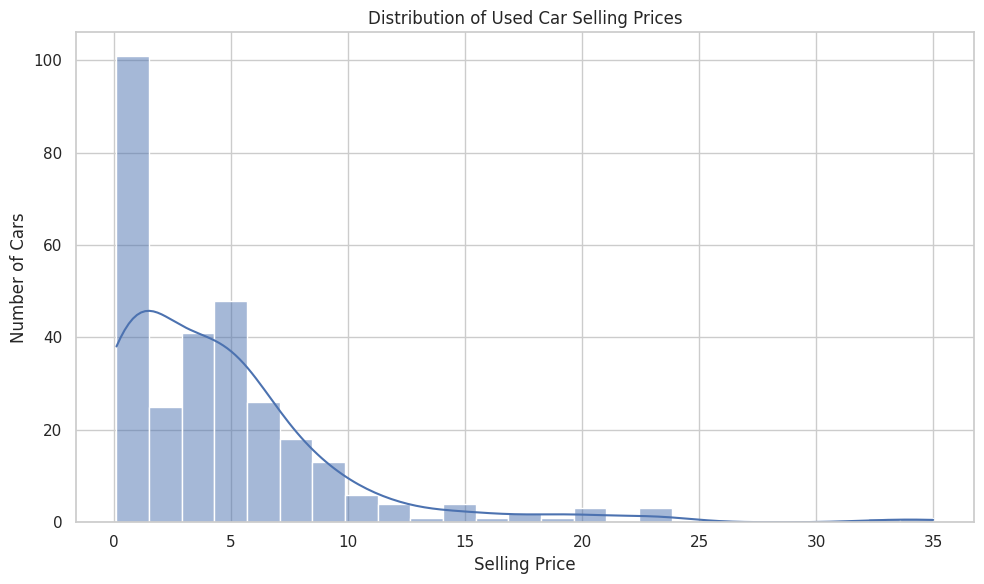

In [4]:
# the distribution of selling prices
# Summary statistics
print("SELLING PRICE SUMMARY")
display(df["Selling_Price"].describe())

print("Skewness:", round(df["Selling_Price"].skew(), 3))

# Histogram with KDE
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Selling_Price",
    kde=True,
    bins=25
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "01_selling_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

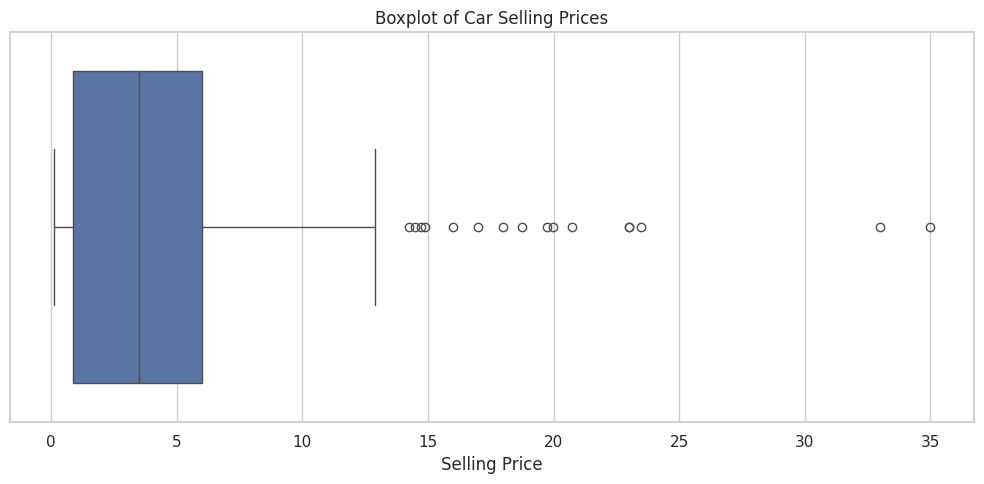

In [5]:
# Selling-price outliers
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Selling_Price"
)

plt.title("Boxplot of Car Selling Prices")
plt.xlabel("Selling Price")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "02_selling_price_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

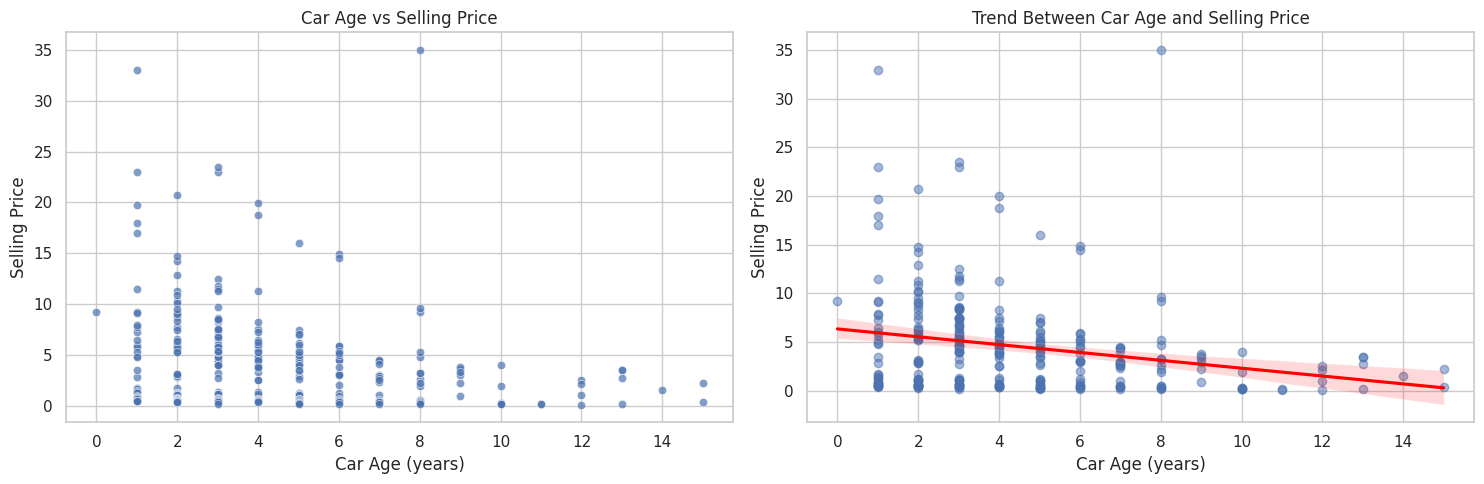

In [6]:
# The relationship between car age and selling price
# Create Car_Age if it was not saved previously
if "Car_Age" not in df.columns:
    df["Car_Age"] = 2018 - df["Year"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price",
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title("Car Age vs Selling Price")
axes[0].set_xlabel("Car Age (years)")
axes[0].set_ylabel("Selling Price")

sns.regplot(
    data=df,
    x="Car_Age",
    y="Selling_Price",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[1]
)
axes[1].set_title("Trend Between Car Age and Selling Price")
axes[1].set_xlabel("Car Age (years)")
axes[1].set_ylabel("Selling Price")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "03_car_age_vs_selling_price.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

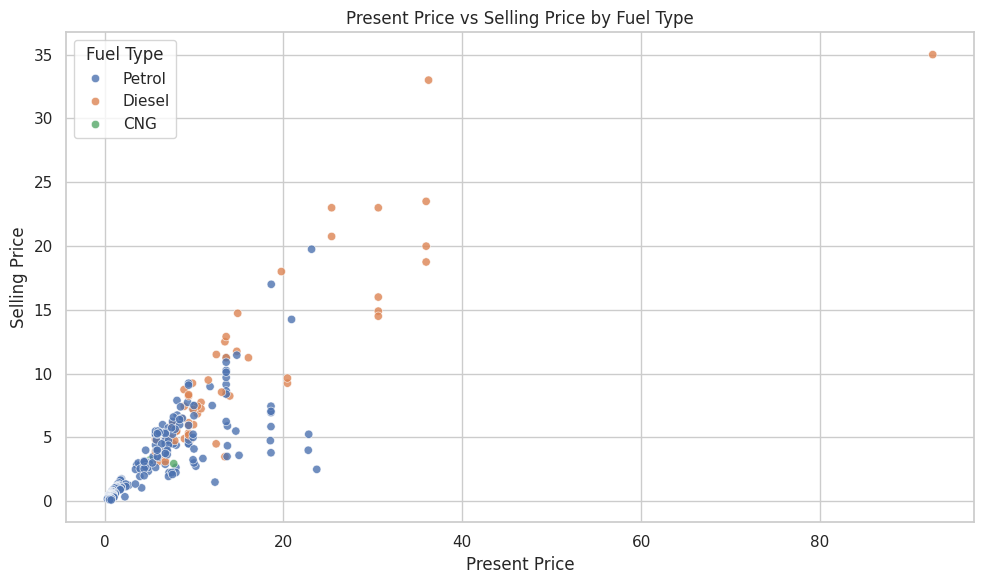

Correlation: 0.876


In [7]:
# The relationship between present price and selling price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Present_Price",
    y="Selling_Price",
    hue="Fuel_Type",
    alpha=0.8
)

plt.title("Present Price vs Selling Price by Fuel Type")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.legend(title="Fuel Type")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "04_present_price_vs_selling_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Correlation:",
    round(df["Present_Price"].corr(df["Selling_Price"]), 3)
)

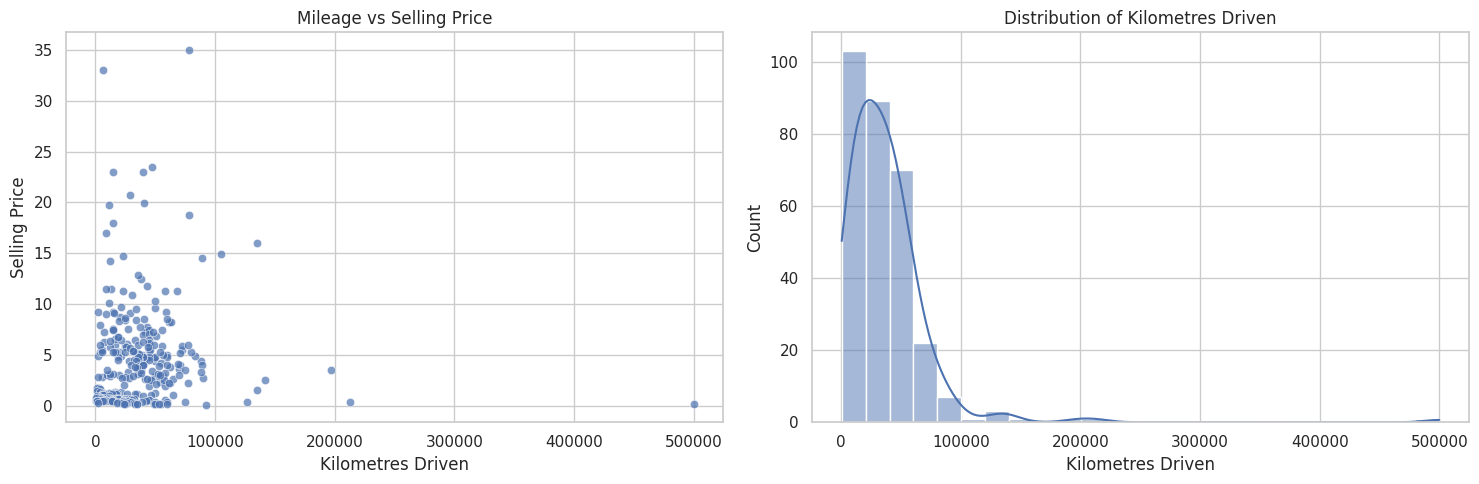

In [8]:
# Mileage and selling price
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    data=df,
    x="Driven_kms",
    y="Selling_Price",
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title("Mileage vs Selling Price")
axes[0].set_xlabel("Kilometres Driven")
axes[0].set_ylabel("Selling Price")

sns.histplot(
    data=df,
    x="Driven_kms",
    bins=25,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Kilometres Driven")
axes[1].set_xlabel("Kilometres Driven")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "05_mileage_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

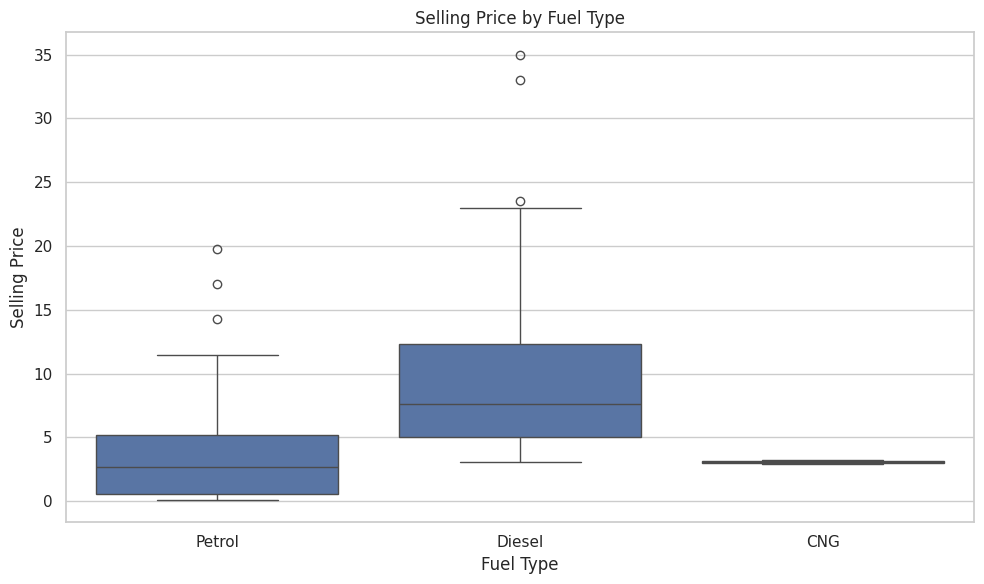

,count,mean,median,min,max
Fuel_Type,,,,,
CNG,2,3.10,3.10,2.95,3.25
Diesel,58,10.10,7.60,3.10,35.00
Petrol,239,3.26,2.65,0.10,19.75


In [9]:
# Selling prices by fuel type
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "06_selling_price_by_fuel_type.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Statistical summary
fuel_summary = (
    df.groupby("Fuel_Type", observed=True)["Selling_Price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(fuel_summary)

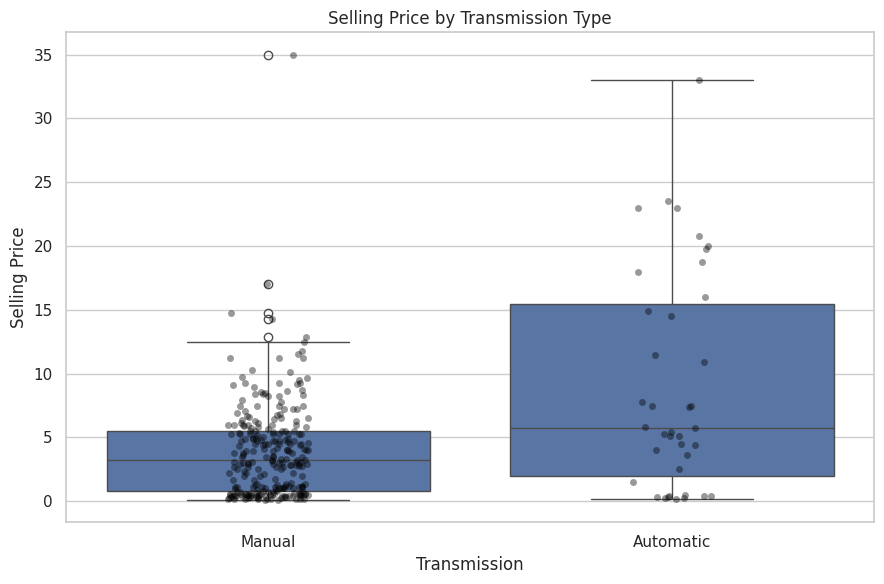

,count,mean,median
Transmission,,,
Automatic,39,9.07,5.75
Manual,260,3.92,3.25


In [10]:
# Selling prices by transmission type
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Transmission",
    y="Selling_Price"
)

sns.stripplot(
    data=df,
    x="Transmission",
    y="Selling_Price",
    color="black",
    alpha=0.4,
    jitter=True
)

plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "07_selling_price_by_transmission.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

transmission_summary = (
    df.groupby("Transmission", observed=True)["Selling_Price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(transmission_summary)

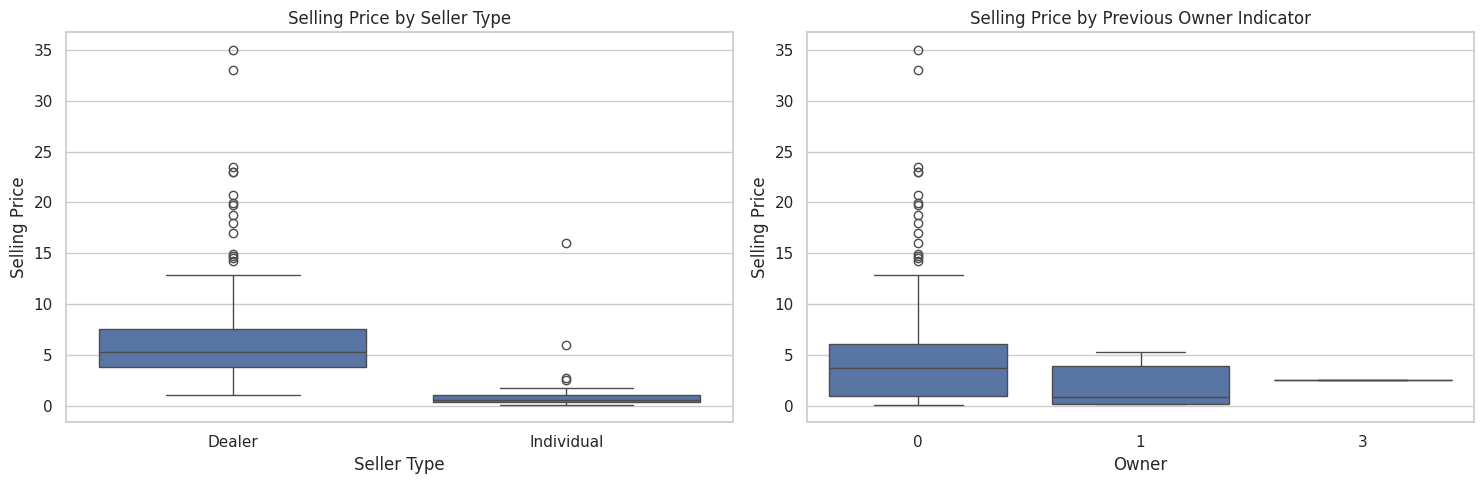

In [11]:
# Selling type and previous ownership
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=df,
    x="Selling_type",
    y="Selling_Price",
    ax=axes[0]
)
axes[0].set_title("Selling Price by Seller Type")
axes[0].set_xlabel("Seller Type")
axes[0].set_ylabel("Selling Price")

sns.boxplot(
    data=df,
    x="Owner",
    y="Selling_Price",
    ax=axes[1]
)
axes[1].set_title("Selling Price by Previous Owner Indicator")
axes[1].set_xlabel("Owner")
axes[1].set_ylabel("Selling Price")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "08_seller_and_owner_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,count,mean,median
Age_Group,,,
0-2 years,85,5.64,4.80
3-5 years,131,4.86,4.60
6-10 years,70,3.38,2.78
Over 10 years,13,1.55,1.50


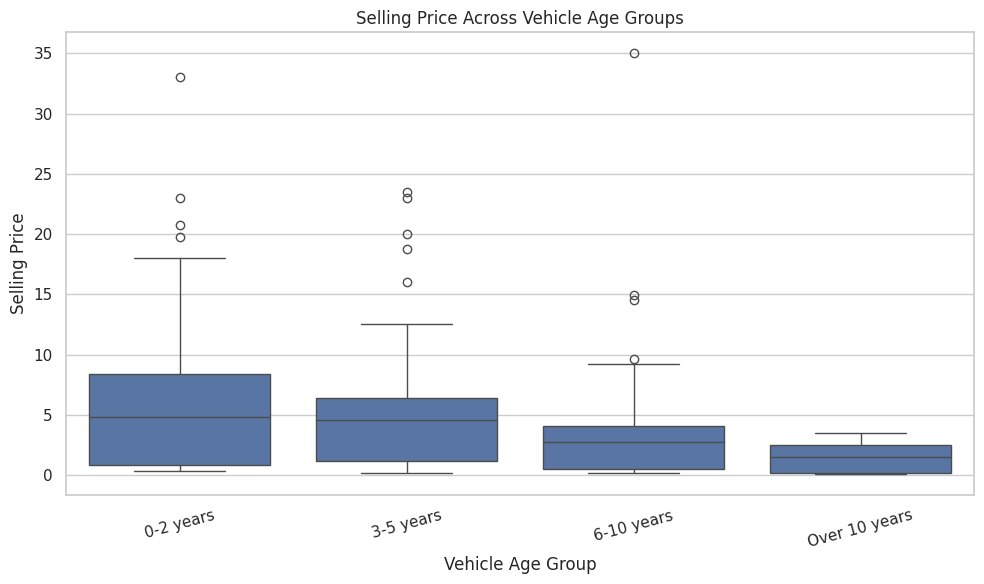

In [12]:
# Depreciation across car-age groups
if "Age_Group" not in df.columns:
    df["Age_Group"] = pd.cut(
        df["Car_Age"],
        bins=[-1, 2, 5, 10, np.inf],
        labels=[
            "0-2 years",
            "3-5 years",
            "6-10 years",
            "Over 10 years"
        ]
    )

age_summary = (
    df.groupby("Age_Group", observed=True)["Selling_Price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(age_summary)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Age_Group",
    y="Selling_Price",
    order=[
        "0-2 years",
        "3-5 years",
        "6-10 years",
        "Over 10 years"
    ]
)

plt.title("Selling Price Across Vehicle Age Groups")
plt.xlabel("Vehicle Age Group")
plt.ylabel("Selling Price")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "09_selling_price_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

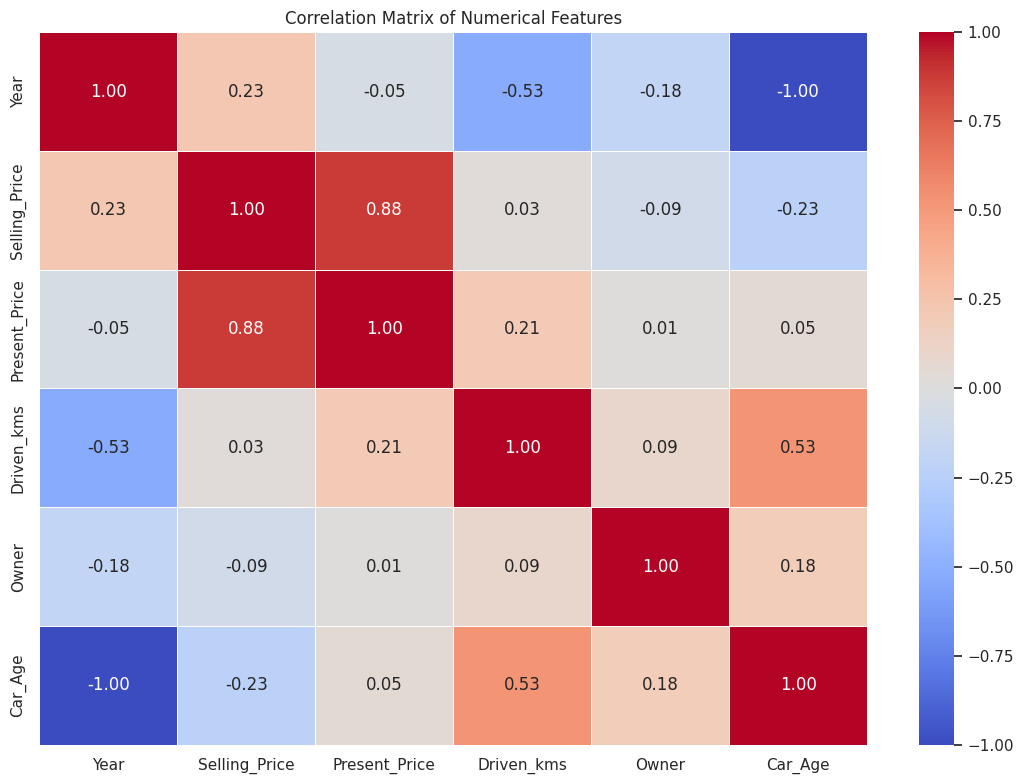

Correlation with Selling_Price:


,Correlation
Selling_Price,1.000000
Present_Price,0.876305
Year,0.234369
Driven_kms,0.028566
Owner,-0.087880
Car_Age,-0.234369


In [13]:
# Numerical correlations
numerical_df = df.select_dtypes(include=np.number)

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "10_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Correlation with Selling_Price:")
display(
    correlation_matrix["Selling_Price"]
    .sort_values(ascending=False)
    .to_frame("Correlation")
)

Models with the highest average selling prices:


,Number_of_Cars,Average_Selling_Price,Median_Selling_Price,Average_Present_Price
Car_Name,,,,
land cruiser,1,35.00,35.00,92.60
fortuner,10,18.25,17.38,30.74
innova,9,12.78,12.50,17.85
creta,3,11.80,11.25,13.60
elantra,2,11.60,11.60,14.79
vitara brezza,1,9.25,9.25,9.83
ciaz,9,7.47,7.45,9.76
city,26,7.42,8.38,11.79
corolla altis,16,7.18,5.68,17.58


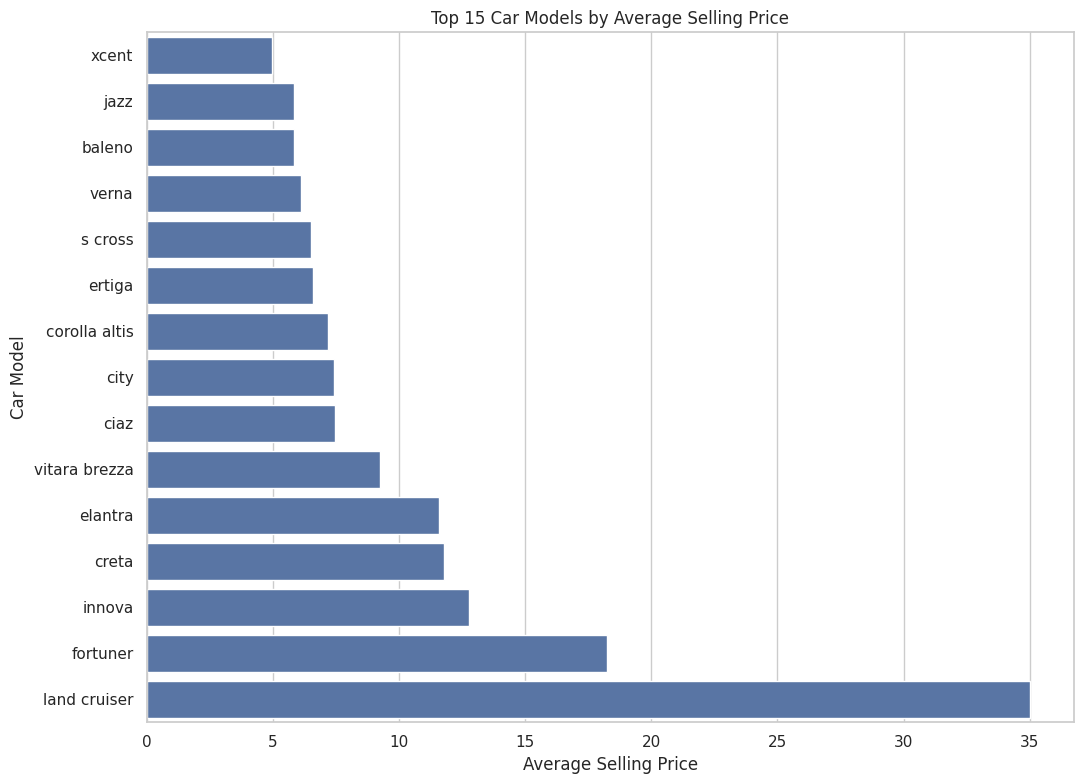

In [14]:
# To Investigate car models and brand identity
model_summary = (
    df.groupby("Car_Name", observed=True)
    .agg(
        Number_of_Cars=("Selling_Price", "size"),
        Average_Selling_Price=("Selling_Price", "mean"),
        Median_Selling_Price=("Selling_Price", "median"),
        Average_Present_Price=("Present_Price", "mean")
    )
    .sort_values(
        "Average_Selling_Price",
        ascending=False
    )
)

print("Models with the highest average selling prices:")
display(model_summary.head(15).round(2))

top_models = model_summary.head(15).sort_values(
    "Average_Selling_Price"
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_models.reset_index(),
    x="Average_Selling_Price",
    y="Car_Name"
)

plt.title("Top 15 Car Models by Average Selling Price")
plt.xlabel("Average Selling Price")
plt.ylabel("Car Model")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "11_car_model_price_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

model_summary.to_csv(
    OUTPUT_DIR / "car_model_price_summary.csv"
)

In [15]:
# Generate an automated EDA summary
eda_summary = pd.DataFrame({
    "Metric": [
        "Number of observations",
        "Number of features",
        "Average selling price",
        "Median selling price",
        "Minimum selling price",
        "Maximum selling price",
        "Average present price",
        "Average kilometres driven",
        "Average car age",
        "Selling price skewness",
        "Correlation: present price vs selling price",
        "Correlation: mileage vs selling price"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df["Selling_Price"].mean(),
        df["Selling_Price"].median(),
        df["Selling_Price"].min(),
        df["Selling_Price"].max(),
        df["Present_Price"].mean(),
        df["Driven_kms"].mean(),
        df["Car_Age"].mean(),
        df["Selling_Price"].skew(),
        df["Present_Price"].corr(df["Selling_Price"]),
        df["Driven_kms"].corr(df["Selling_Price"])
    ]
})

display(eda_summary.round(3))

eda_summary.to_csv(
    OUTPUT_DIR / "eda_summary.csv",
    index=False
)

print("EDA summary saved successfully.")

,Metric,Value
0,Number of observations,299.000
1,Number of features,11.000
2,Average selling price,4.590
3,Median selling price,3.510
4,Minimum selling price,0.100
5,Maximum selling price,35.000
6,Average present price,7.541
7,Average kilometres driven,36916.753
8,Average car age,4.385
9,Selling price skewness,2.537


EDA summary saved successfully.
